### REINFORCE, Actor-Critic

1. REINFORCE
- 에피소드 전체를 모은 뒤 Monte Carlo return `G_t`를 사용해 정책을 업데이트
- 정책 경사의 기본 개념이 명료함. 분산이 크고 에피소드 종료까지 기다려야 함

2. Actor-Critic
- Actor는 정책 `π(a|s)`를 Critic은 `V(s)`를 학습
- TD 목표: `y_t = r_t + γ(1-d_t)V(s_{t+1})`
- Advantage
    - 내가 선택한 행동이 평소 기대했던 것보다 얼마나 좋았는가를 나타내는 값
    - V(s): 현재 상태에서 앞으로 얼마나 많은 보상을 받을 것으로 예상
    - Advantage A(s, a): 현재 상태에서 행동이 평균적인 기대보다 얼마나 좋은가?
        - 양수면 그 행동의 선택 확률을 높임
        - 음수면 그 행동의 선택 확률을 낮임
    - `A_t ≈ y_t − V(s_t)`
```
    평소 예상 점수는 70점이었는데, 실제로 90점을 받음
        Advantage = 90 - 70 = +20
    예상 점수는 70점이었는데, 실제로 50점을 받음
        Advantage = 50 - 70 = -20
```
- Actor 손실 `L_actor = −log π(a_t|s_t) · stop_gradient(A_t)`.
- Critic 손실 `L_critic = (V(s_t)−y_t)^2`.




# **1. A2C**
A2C(Advantage Actor-Critic)는 정책(Actor)과 가치함수(Critic)를 함께 학습하면서, Advantage를 이용해 정책의 방향을 정하는 Actor-Critic 계열 알고리즘. A2C는 N개의 환경이 일정한 길이 T만큼 동시에 경험을 수집한 뒤, 그 경험을 합쳐 한 번에 신경망을 갱신함

### A2C의 배경
- 단일 환경에서 연속으로 수집한 경험은 비슷한 장면이 반복
- 환경 여러 개에서 서로 다른 상태를 경험하면 학습 배치가 다양해짐
- 한 스텝만 보지 않고 n-step return을 사용하면 조금 더 먼 미래의 보상을 반영함
- 동기식이므로 모든 환경이 모인 뒤 갱신해 업데이트 절차를 이해/재현하기 쉬움


$$
한\ 스텝\ TD: G_t^{(1)}=r_t+\gamma V(s_{t+1})
$$

$$
n-step\ Return: G_t^{(n)}=r_t+\gamma r_{t+1}+\cdots+\gamma^{n-1}r_{t+n-1}+\gamma^n V(s_{t+n})
$$

$$
Advantage: A_t=G_t^{(n)}-V(s_t)
$$

$$
전체\ 손실: L=-\mathbb E[\log\pi(a_t|s_t)\,\mathrm{stopgrad}(A_t)]+c_v\mathbb E[(V(s_t)-G_t^{(n)})^2]-c_e\mathbb E[H(\pi(\cdot|s_t))
$$

> n-step의 `n`은 신경망 층 수가 아니라 앞으로 관찰한 보상 스텝 수임

```
r_0 = 1 : 첫 번째 행동 후 받은 보상
r_1 = 1 : 두 번째 행동 후 받은 보상
r_2 = 1 : 세 번째 행동 후 받은 보상
γ = 0.9 : 미래 보상에 적용하는 할일율
V(s_3) = 5 : 세 번째 행동 후 상태에서 앞으로 받을 것으로 예상되는 보상
V(s_0) = 4 : 처음 상태에서 앞으로 받을 것으로 예상되는 보상
```
문제
1. AI가 3번의 행동으로 실제 받은 보상의 합계는 얼마?
    - 1+1+1 = 3
2. 미래 보상에 할인율을 적용하여 계산한 3-step Return은 얼마?
$$
    G_0^{(3)}=1+0.9(1)+0.9^2(1)+0.9^3(5)=6.355
$$
    - 실제로 받은 보상은 3점이지만, 3번 행동한 이후의 미래 예상 가치까지 포함하고 할인율을 적용했기 때문에 6.355가 나옴
3. 처음 예상했던 가치와 비교한 Advantage는 얼마?
    - Advantage는 처음 예상했던 가치와 새롭게 계산한 목표 가치의 차이
        - Critic은 현재 상태의 가치를 4점이라고 예상
        - 3번 행동한 경험과 미래 예상 가치를 이용해 계산한 값은 6.355
        - 6.355 - 4 = 2.355
4. 위 결과처럼 Advantage가 양수라는 것은 어떤 의미?
    - 처음 예상했던 가치보다 새롭게 계산한 목표 가치가 2.355점 높다는 의미
    - Actor는 처음 상태 s0에서 선택했던 행동의 확률을 높이는 방향으로 학습

In [1]:
gamma = 0.9
rewards = [1.0, 1.0, 1.0]
bootstrap_value = 5.0
running = bootstrap_value
for r in reversed(rewards):
    running = r + gamma * running
print('3-step return: ', round(running, 3))
print('advantage: ', round(running - 4.0, 3))

3-step return:  6.355
advantage:  2.355


In [2]:
import random, time, math, copy
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.distributions import Categorical, Normal
import gymnasium as gym

In [3]:
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cuda


In [4]:
class DiscreteActorCritic(nn.Module):
    def __init__(self, obs_dim=4, n_actions=2, hidden=128):
        super().__init__()
        self.body = nn.Sequential(
            nn.Linear(obs_dim, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh()
        )
        self.actor = nn.Linear(hidden, n_actions)
        self.critic = nn.Linear(hidden, 1) 

    def forward(self, states):
        features = self.body(states)
        logits = self.actor(features)
        values = self.critic(features).squeeze(-1)
        return logits, values

In [5]:
net_test = DiscreteActorCritic().to(DEVICE)
logits, values = net_test(torch.zeros(4, 4, device=DEVICE))
print('logits:', logits.shape, 'values:', values.shape)

logits: torch.Size([4, 2]) values: torch.Size([4])


1. 환경 N개를 만들고 상태를 모음
2. T번 반복하면서 같은 정책으로 각 환경의 행동을 선택
3. 보상, 종료 여부, 가치, 행동 로그확률, 엔트로피를 저장
4. 각 환경이 종료되면 다음 에피소드로 리셋. 단, 종료 전 마지막 관측에서 계산한 부트스트랩 가치를 보존
5. 역순으로 n-step Return을 계산
6. Actor/Critic/Entropy 손실을 합산하고 optimizer.step()을 호출

In [6]:
def set_seed(seed=2026):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

In [7]:
def make_envs(n=4, name="CartPole-v1", seed=2026):
    envs = [gym.make(name) for _ in range(n)]
    states = []
    for i, env in enumerate(envs):
        env.action_space.seed(seed + i)
        state, _ = env.reset(seed=seed + i)
        states.append(state)
    return envs, np.asanyarray(states, dtype=np.float32)

In [8]:
# 4개의 게임을 각각 5스텝씩 실행하고, 총 20개의 경험을 모아 한 번 학습하는 과정을 300회 반복
# 300 * 4 * 5 = 6000(총 환경 스텝 수)
def train_a2c(updates=1000, n_envs=4, rollout_steps=5, seed=2026, gamma=0.99, lr=7e-4, value_coef=0.5, entropy_coef=0.01, print_every=50):
    set_seed(seed)
    # envs = [환경0, 환경1, 환경2, 환경3]
    # states = [환경0의 현재 상태, 환경1의 현재 상태 ..]
    # 상태: 카트위치, 속도, 막대기 기울기, 각속도
    envs, states = make_envs(n_envs, seed=seed)
    model = DiscreteActorCritic().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    # 각 환경에서 현재 진행 중인 에피소드의 누적 보상을 저장
    episode_scores = np.zeros(n_envs, dtype=np.float64)
    completed = []
    history = []

    try:
        for update in range(1, updates + 1):
            # logps: 실제 선택한 행동의 로그 확률
            # vals: Critic이 예측한 현재 상태 가치
            # bootstraps: 다음 상태에서의 예상 가치
            # boundaries: 에피소드 종료 여부
            logps, vals, rewards, bootstraps = [], [], [], []
            boundaries, entropies = [], []

            for t in range(rollout_steps):
                x = torch.as_tensor(states, dtype=torch.float32, device=DEVICE)
                logits, value = model(x)
                dist = Categorical(logits=logits)
                actions = dist.sample()
                logps.append(dist.log_prob(actions))
                vals.append(value)
                entropies.append(dist.entropy())

                next_states, rs, bs, ends = [], [], [], []
                for i, env in enumerate(envs):
                    # ns: 다음상태
                    ns, r, terminated, truncated, _ = env.step(int(actions[i].item()))
                    episode_scores[i] += float(r)
                    # 두 종료 조건 중 하나라도 참이면 현재 에피소드가 끝났다고 판단
                    boundary = bool(terminated or truncated)
                    # rs: 즉시 보상
                    rs.append(float(r))
                    # ends: 에피소드 경계 여부
                    ends.append(boundary)
                    # bs: 종료 직전 다음 상태와 실제 종료 여부
                    # ns를 저장하는 이유는 truncated=True일 때 다음 상태 가치를 이용해 Bootstrap을 계산해야 하기 때문
                    bs.append((ns, bool(terminated)))
                    if boundary:
                        # 환경이 종료되었다면
                        # 1. 종료된 에피소드의 최종 보상을 저장
                        # 2. 해당 환경의 누적 보상을 0으로 초기화
                        # 3. env.reset()으로 새로운 에피소드를 시작
                        completed.append(float(episode_scores[i]))
                        episode_scores[i] = 0.0
                        ns, _ = env.reset()
                        # ns는 종료되지 않았다면 해동 후의 다음 상태, 종료되었다면 새로 초기화한 상태가 저장
                    next_states.append(ns)
                # Bootstrap
                # 아직 직접 경험하지 않은 미래의 보상을 Critic이 예측한 가치로 대신 계산하는 방법
                # 5스텝까지만 진행했지만 게임은 끝나지 않음 > 5스텝 이후에 받을 보상은 아직 알 수 없음
                # Critic이 다음 상태의 가치를 10점이라도 예측했다면, 그 값을 미래 보상의 추정치로 이용
                # bs: [(환경0의 다음 상태, False), (환경1의 다음 상태, True) ...]
                bootstrap_x = torch.as_tensor(
                    np.asanyarray([item[0] for item in bs], dtype=np.float32), device=DEVICE
                )

                with torch.no_grad():
                    _, bootstrap_values = model(bootstrap_x)
                    """
                    bootstrap_value = [12.0, 8.0, 15.0, 20.0]
                    terminated=True > 1
                    terminated=False > 0
                    환경 0, 다음 상태 가치 12.0, terminated False > 최종 Bootstrap 12
                    환경 1, 다음 상태 가치 8.0, terminated True > 최종 Bootstrap 0 
                    ...
                    """
                    true_terminal = torch.tensor(
                        [float(item[1]) for item in bs], device=DEVICE
                    )
                    bootstrap_values = bootstrap_values * (1.0 - true_terminal)

                rewards.append(torch.tensor(rs, dtype=torch.float32, device=DEVICE))
                bootstraps.append(bootstrap_values)
                boundaries.append(torch.tensor(ends, dtype=torch.bool, device=DEVICE))
                states = np.asanyarray(next_states, dtype=np.float32)

            # 5스텝 동안 얻은 보상과 미래 예상 가치를 역순으로 합산
            # 마지막 스텝의 미래 가치를 먼저 알아야 이전 스탭의 Return을 계산할 수 있음
            """
                rewards = [1, 1, 1]
                gamma = 0.9
                next_value = 5
                
                역순 계산
                마지막 Bootstrap은 5
                t=2 > 1 + 0.9 * 5
                t=1 > 1 + 0.9 * 5.5 
                t=0 > 1 + 0.9 * 5.95 
            """
            running = bootstraps[-1]
            targets = [None] * rollout_steps
            for t in reversed(range(rollout_steps)):
                # 환경0이 세 번째 스텝에서 종료되고 네 번째 스텝부터 새로운 게임이 시작된다면 
                # 이전 게임의 Return에 새로운 게임의 보상을 더하면 안됨
                running = torch.where(boundaries[t], bootstraps[t], running)
                running = rewards[t] + gamma * running
                targets[t] = running

            target_t = torch.stack(targets).detach()
            value_t = torch.stack(vals)
            logp_t = torch.stack(logps)
            entropy_t = torch.stack(entropies)
            advantage = target_t - value_t

            actor_loss = -(logp_t * advantage.detach()).mean()
            critic_loss = advantage.square().mean()
            entropy_bonus = entropy_t.mean()
            loss = actor_loss + value_coef * critic_loss - entropy_coef * entropy_bonus

            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 0.5)
            optimizer.step()

            recent = float(np.mean(completed[-20:])) if completed else np.nan
            history.append({'update': update, 'episodes_done': len(completed),
                            'recent20_reward': recent, 'loss': float(loss.item())})
            if update % print_every == 0:
                print(f'A2C update {update:4d}/{updates} | 종료 에피소드 {len(completed):4d} '
                      f'| 최근20 평균 {recent:7.2f}')

    finally:
        for env in envs:
            env.close()
    return model, pd.DataFrame(history), completed


In [9]:
a2c_model, a2c_hist, a2c_scores = train_a2c(updates=3000, n_envs=4, rollout_steps=5, seed=2026, print_every=50)

A2C update   50/3000 | 종료 에피소드   34 | 최근20 평균   28.30
A2C update  100/3000 | 종료 에피소드   69 | 최근20 평균   27.95
A2C update  150/3000 | 종료 에피소드  115 | 최근20 평균   17.60
A2C update  200/3000 | 종료 에피소드  152 | 최근20 평균   24.60
A2C update  250/3000 | 종료 에피소드  177 | 최근20 평균   37.90
A2C update  300/3000 | 종료 에피소드  210 | 최근20 평균   35.30
A2C update  350/3000 | 종료 에피소드  234 | 최근20 평균   40.85
A2C update  400/3000 | 종료 에피소드  256 | 최근20 평균   42.20
A2C update  450/3000 | 종료 에피소드  280 | 최근20 평균   44.85
A2C update  500/3000 | 종료 에피소드  298 | 최근20 평균   52.25
A2C update  550/3000 | 종료 에피소드  322 | 최근20 평균   40.95
A2C update  600/3000 | 종료 에피소드  342 | 최근20 평균   54.25
A2C update  650/3000 | 종료 에피소드  361 | 최근20 평균   47.40
A2C update  700/3000 | 종료 에피소드  381 | 최근20 평균   45.50
A2C update  750/3000 | 종료 에피소드  405 | 최근20 평균   43.95
A2C update  800/3000 | 종료 에피소드  424 | 최근20 평균   52.50
A2C update  850/3000 | 종료 에피소드  443 | 최근20 평균   45.50
A2C update  900/3000 | 종료 에피소드  465 | 최근20 평균   43.90
A2C update  950/3000 | 종료 에피

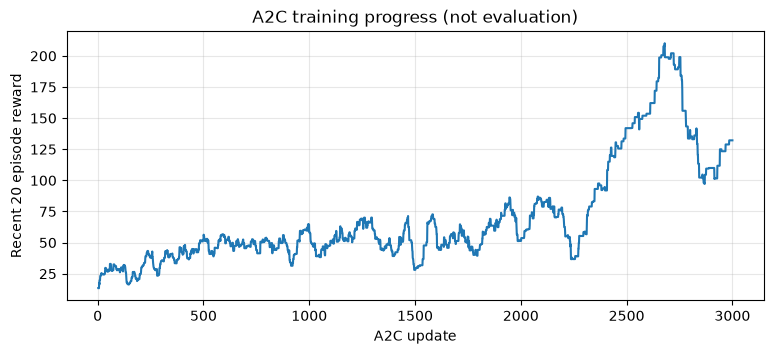

In [10]:
plt.figure(figsize=(9, 3.5))
plt.plot(a2c_hist['update'], a2c_hist['recent20_reward'])
plt.xlabel('A2C update')
plt.ylabel('Recent 20 episode reward')
plt.title('A2C training progress (not evaluation)')
plt.grid(alpha=0.3)
plt.show()

# **2. A3C**
- A3C(Asynchronous Advantage Actor-Critic)
- A2C는 Worker들이 데이터를 수집한 뒤 모두 모일 때까지 기다림 > 느린 Worker가 있으면 전체 업데이트가 늦어짐 
- A3C는 각 Worker가 독립적으로 환경을 탐험하고 계산한 기울기를 공유 모델에 비동기적으로 반영

```
Worker 1: 환경 1 > 경험 > Local Gradient
Worker 2: 환경 2 > 경험 > Local Gradient    > Global Actor-Critic 파라미터
Worker 3: 환경 3 > 경험 > Local Gradient
...
```

- Global network: 여러 Worker가 공동으로 개선하는 모델
- Local network: 각 Worker가 행동을 선택하고 기울기를 계산할 때 쓰는 복사본
- 비동기: 모든 Worker가 한 번에 끝나기를 기다리지 않음

n-step return: $R_t=\sum_{k=0}^{n-1}\gamma^k r_{t+k}+\gamma^n V(s_{t+n})$

>  비동기라는 말은 "무조건 더 빠르다"는 뜻은 아님. CPU 코어 수, 공유 파라미터 경쟁, 프로세스 생성 비용에 영향을 받음. 

보상이 $[1,1,1]$, $\gamma=0.9$, 3스텝 후 가치가 2라면 $R=1+0.9+0.81+0.9^3\times2=4.168$. 현재 가치가 3이라면 Advantage는 1.168

In [14]:
def nstep_return(rewards, bootstrap, gamma=0.9):
    R = bootstrap
    for r in reversed(rewards):
        R = r + gamma * R
    return R
print('3-step return: ', nstep_return([1, 1, 1], 2))
print('Advantage: ', nstep_return([1, 1, 1], 2)-3)

3-step return:  4.168
Advantage:  1.1680000000000001


# **3. PPO**
- 한 번의 경험으로 정책을 급격하게 바꾸지 못하도록 함
- 기존 정책을 안정적으로 개선하기 위한 Actor-Critic 계열 알고리즘

```
현재 정책에서 오른쪽 행동 확률이 40%였는데 한 번의 학습으로 95%가 되면, 이전에 수집한 데이터가 새 정책을 잘 대표하지 못할 수 있음.
```
> PPO는 이전 정책과 새 정책의 행동 확률을 비교하고, 업데이트가 지나치게 커지지 않도록 목적함수에 제한을 둠


### 확률 비율
- 상태 s에서 실제로 선택한 행동 a의 확률을 비교

$$r_t(\theta)=\frac{\pi_\theta(a_t\mid s_t)}{\pi_{\theta_{old}}(a_t\mid s_t)}$$

- 분모: 데이터를 수집하던 당시 정책이 그 행동을 선택할 확률
- 분자: 현재 업데이트 중인 정책이 같은 행동을 선택할 확률
- 비율이 1: 확률이 그대로
- 비율이 1.5: 확률이 이전보다 50% 증가
- 비율이 0.7: 확률이 이전보다 30% 감소
    - 예) 예전 정책이 왼쪽을 선택할 확률 0.4, 새 정책은 0.6이라면 r = 0.6 / 0.4 = 1.5

> 행동이 여러 개라도 수집 당시 실제 선택한 행동의 확률을 사용

In [1]:
old_probability = 0.4
new_probability = 0.6
ratio = new_probability / old_probability
print(f"확률 비율: {ratio:.2f}, 이전 대비 변화: {(ratio-1)*100:.0f}%")

확률 비율: 1.50, 이전 대비 변화: 50%


### Advantage
- 실제로 얻은 결과 - Critic이 기대한 결과
    - A > 0: 행동을 더 자주 선택하도록 유도
    - A < 0: 행동을 덜 자주 선택하도록 유도
    - A $\approx0:$: 큰 변화가 필요 없음

### Clipping

$$L^{CLIP}=\mathbb{E}_t[\min(r_t A_t,\;\operatorname{clip}(r_t,1-\epsilon,1+\epsilon)A_t)]$$

$\epsilon=0.2$ 이면 비율을 목적함수 계산에서 0.8~1.2로 자름

In [3]:
import numpy as np

In [6]:
for ratio, advantage in [(1.5, 2), (0.7, 2), (1.5, -2), (0.7, -2)]:
    raw = ratio * advantage
    clipped = np.clip(ratio, 0.8, 1.2) * advantage
    objective = min(raw, clipped)
    print(f"r={ratio:.1f}, A={advantage:+.0f}, 원래={raw:+.2f}, 잘린={clipped:+.2f}, PPO={objective:+.2f}")

# PPO=+2.40: 좋은 행동 확률을 지나치게 높이는 이득 제한
# PPO=+1.40: 좋은 행동 확률을 낮추는 손해는 그대로 반영
# PPO=-3.00: 나쁜 행동 확률을 높이는 손해는 그대로 반영
# PPO=-1.60: 나쁜 행동 확률을 지나치게 낮추는 이득 제한
# min(): 정책을 좋은 방향으로 지나치게 바꾸어 얻는 추가 보상을 제한하면서, 나쁜 방향으로 바뀌는 경우는 페널티를 유지하기 때문. 손실 함수는 이를 최대화하는 대신 음수로 바꾸어 최소화

r=1.5, A=+2, 원래=+3.00, 잘린=+2.40, PPO=+2.40
r=0.7, A=+2, 원래=+1.40, 잘린=+1.60, PPO=+1.40
r=1.5, A=-2, 원래=-3.00, 잘린=-2.40, PPO=-3.00
r=0.7, A=-2, 원래=-1.40, 잘린=-1.60, PPO=-1.60
